In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (needed for 3D)
from ipywidgets import interact, FloatSlider, Checkbox
from sklearn.decomposition import PCA

# ----- synthetic 3D cloud (nontrivial covariance so PCs are tilted)
rng = np.random.default_rng(0)
n = 1000
base = rng.normal(0, 1, size=(n, 3))
# base = rng.standard_normal((n, 3))
A = np.array([[2.0, 0.8, 0.4],
              [0.0, 1.2, 0.6],
              [0.0, 0.0, 0.7]])
X = base @ A.T + np.array([2.0, -1.0, 0.5])  # shift the mean a bit

# ----- PCA
pca = PCA(n_components=3).fit(X)
mu = pca.mean_
pcs = pca.components_          # columns are directions in sklearn? -> rows (each PC as a row)
vals = pca.explained_variance_

# utility: equal aspect for 3D
def set_axes_equal(ax):
    xlim = np.array(ax.get_xlim3d())
    ylim = np.array(ax.get_ylim3d())
    zlim = np.array(ax.get_zlim3d())
    ranges = np.array([xlim[1]-xlim[0], ylim[1]-ylim[0], zlim[1]-zlim[0]])
    centers = np.array([xlim.mean(), ylim.mean(), zlim.mean()])
    radius = 0.5 * ranges.max()
    ax.set_xlim3d([centers[0]-radius, centers[0]+radius])
    ax.set_ylim3d([centers[1]-radius, centers[1]+radius])
    ax.set_zlim3d([centers[2]-radius, centers[2]+radius])

def plot_pca_3d(elev=20.0, azim=45.0, show_plane=True, point_alpha=0.25):
    fig = plt.figure(figsize=(6,6))
    ax = fig.add_subplot(111, projection='3d')

    # scatter
    ax.scatter(X[:,0], X[:,1], X[:,2], s=10, alpha=point_alpha)

    # PC1 axis (line through mean ± k * sqrt(variance))
    k = 3.0
    d1 = pcs[0]                           # PC1 direction
    L = k * np.sqrt(vals[0])
    p1_plus  = mu + L * d1
    p1_minus = mu - L * d1
    ax.plot([p1_minus[0], p1_plus[0]],
            [p1_minus[1], p1_plus[1]],
            [p1_minus[2], p1_plus[2]],
            linewidth=1, color='orange')

    # orthogonal complement to PC1 = plane spanned by PC2 & PC3 through the mean
    if show_plane:
        d2, d3 = pcs[1], pcs[2]
        # build a small mesh in (d2, d3)
        grid_extent = 2.5 * np.sqrt(vals[1] + vals[2])
        u = np.linspace(-grid_extent, grid_extent, 15)
        v = np.linspace(-grid_extent, grid_extent, 15)
        U, V = np.meshgrid(u, v)
        plane = mu[None, None, :] + U[..., None]*d2[None, None, :] + V[..., None]*d3[None, None, :]
        ax.plot_surface(plane[...,0], plane[...,1], plane[...,2], alpha=0.2, linewidth=0, antialiased=True, color='orange')

    # cosmetics
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    set_axes_equal(ax)
    plt.title("PCA in 3D: PC1 axis and its orthogonal complement (plane)")
    plt.savefig('pca-3d.png', dpi=300)
    plt.show()
    

interact(
    plot_pca_3d,
    elev=FloatSlider(min=-10, max=80, step=1, value=36, description='elev'),
    azim=FloatSlider(min=-180, max=180, step=2, value=138, description='azim'),
    show_plane=Checkbox(value=True, description='show plane (⊥ PC1)'),
    point_alpha=FloatSlider(min=0.05, max=1.0, step=0.05, value=0.15, description='point α')
)


interactive(children=(FloatSlider(value=36.0, description='elev', max=80.0, min=-10.0, step=1.0), FloatSlider(…

<function __main__.plot_pca_3d(elev=20.0, azim=45.0, show_plane=True, point_alpha=0.25)>

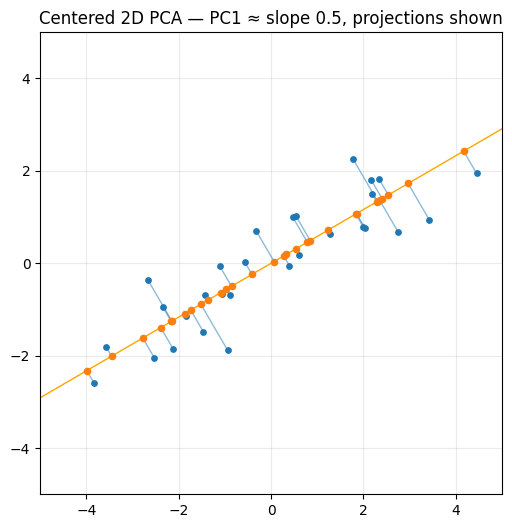

Estimated PC1 slope ≈ 0.58


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# --- target: PC1 ~ slope 0.5
rng = np.random.default_rng(8)
n = 30  # small, to keep projection lines clear

# Desired PC1 direction (normalize)
u1 = np.array([1.0, 0.5])
u1 = u1 / np.linalg.norm(u1)

# Orthogonal complement (normalize)
u2 = np.array([-u1[1], u1[0]])
u2 = u2 / np.linalg.norm(u2)

# Eigenvalues: strong anisotropy so PC1 is clear
lam1, lam2 = 4.0, 0.3

# Build covariance: C = R diag(lam1, lam2) R^T, with columns = eigenvectors
R = np.column_stack([u1, u2])
C = R @ np.diag([lam1, lam2]) @ R.T

# Sample centered cloud with this covariance
Z = rng.standard_normal((n, 2))
X = Z @ np.linalg.cholesky(C).T

# Enforce exact centering (sample mean ~ 0, make it exactly 0)
X = X - X.mean(axis=0)

# --- PCA via eigendecomposition of covariance
S = np.cov(X, rowvar=False, bias=False)
vals, vecs = np.linalg.eigh(S)          # ascending
idx = vals.argsort()[::-1]
vals, vecs = vals[idx], vecs[:, idx]
u1_hat, u2_hat = vecs[:, 0], vecs[:, 1] # estimated PCs
mu = X.mean(axis=0)

# --- helper: project onto PC1 line through the mean (which is 0 here)
def proj_on_pc1(x, mu, u1):
    return mu + np.dot(x - mu, u1) * u1

# --- plot
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], s=15, label="points", zorder=3)

# PC1 line (estimated): length scales with sqrt(variance)
L1 = 3.0 * np.sqrt(vals[0])
p1a, p1b = mu - L1 * u1_hat, mu + L1 * u1_hat
plt.plot([p1a[0], p1b[0]], [p1a[1], p1b[1]], linewidth=1, label="PC1 axis", zorder=2, color='orange')

# PC2 (for context)
L2 = 3.0 * np.sqrt(vals[1])
p2a, p2b = mu - L2 * u2_hat, mu + L2 * u2_hat
#plt.plot([p2a[0], p2b[0]], [p2a[1], p2b[1]], linewidth=1, alpha=0.4, label="PC2", zorder=1, color='red')

# projection lines from each point to PC1
proj_points = np.array([proj_on_pc1(x, mu, u1_hat) for x in X])
for x, xp in zip(X, proj_points):
    plt.plot([x[0], xp[0]], [x[1], xp[1]], linewidth=1, color='C0', alpha=0.5)

# projected points on the axis
plt.scatter(proj_points[:, 0], proj_points[:, 1], s=20, marker='o', label="projection on PC1", zorder=4)

# cosmetics
plt.gca().set_aspect('equal', adjustable='box')
plt.title("Centered 2D PCA — PC1 ≈ slope 0.5, projections shown")
plt.grid(True, alpha=0.25)
#plt.legend(loc="best")
plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.savefig('data-pca-proj-1d.png', dpi=300)
plt.show()

# Optional: print the fitted PC1 slope to verify it's ~0.5
slope = u1_hat[1] / (u1_hat[0] + 1e-12)
print(f"Estimated PC1 slope ≈ {slope:.2f}")
